In [1]:
# Only in Colab: work inside the homework folder of Drive (the .py files are there)
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir("/content/drive/MyDrive/POSGRADOS/HUNGRIA/MASTER/1/FNANCIAL PROCESS /HOMEWORKS/2_HW_LECTURE_4")
except ImportError:
    pass
print(os.getcwd())

/home/claude/hw2task/final


**Homework 2: Implement calibrator for Tree. Part 2: Task. Q1: the calibrate method**

*Task: Write a calibrate method which, for a given number of steps parameter, computes the up step size for which a Balanced Binomial Tree model returns the specified price for a given European call. (In practice option prices can be observed in the market, so it makes sense to assume it is given).* *Hint: To do it you will need to use a root solver, I recommend using scipy.optimize.minimize.*

Market price = Black-Scholes price of Homework 1 with $\sigma = 0.2$, $r = -\ln 0.95$. Running example: $S_0 = K = 1$, $T = 1$, yearly $DF = 0.95$.

**Professor's code** (`Binomial_tree_coding.ipynb`, cells 1, 3, 5, 8 and 13), unchanged (file `prof_tree.py`)

In [2]:
import numpy as np
from scipy.optimize import minimize
from collections.abc import Callable


def european_call_payoff(S: float, K: float) -> float:
    return max(S-K, 0.0)


def create_spot_tree(spot: float, spot_mult_up: float, spot_mult_down: float, steps: int) -> list[list[float]]:
    previous_level = [spot]
    tree = [previous_level]
    for _ in range(steps):
        new_level = [s * spot_mult_down for s in previous_level]
        new_level += [previous_level[-1] * spot_mult_up]
        tree += [new_level]
        previous_level = new_level
    return tree


def create_discounted_price_tree(spot_tree: list[list[float]], discount_factor: float, K: float, diag: int = 0) -> list[list[float]]:
    spot = spot_tree[0][0]
    spot_mult_up = spot_tree[1][-1]
    spot_mult_down = spot_tree[1][0]
    p_up = ((1 / discount_factor - spot_mult_down) /
                   (spot_mult_up - spot_mult_down))
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    if diag > 0:
        print("risk-neutral measure: ")
        print(('%.3f' % p_up, '%.3f' % p_down))
        # init delta tree
        delta_tree = [[np.nan for _ in level] for level in spot_tree[:-1]] #delta makes no sense for leaves
    # going backwards, payoff is known in leaves
    for i in range(len(spot_tree[-1])):
        spot = spot_tree[-1][i]
        discounted_continuation_value = discount_factor**(steps) * european_call_payoff(spot, K)
        continuation_value_tree[-1][i] = discounted_continuation_value
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = p_up * continuation_value_tree[step + 1][i] + \
                                            p_down * continuation_value_tree[step + 1][i + 1]
            if diag > 0:
                delta_tree[step][i] = ((continuation_value_tree[step + 1][i] - continuation_value_tree[step + 1][i + 1]) 
                                       / (spot_tree[step + 1][i] - spot_tree[step + 1][i + 1]))
    if diag > 0:
        print("delta: ")
        delta_tree_readable = [['%.3f' % e for e in n] for n in delta_tree]
        print(delta_tree_readable)
    return continuation_value_tree


def calcBalancedDownStep(spot_mult_up: float, discount_factor: float) -> (float, float):
    return spot_mult_up - 2 * (spot_mult_up - 1 / discount_factor)

**Test of the professor's code** (cells 6 and 14): balanced tree, $p_{up} = p_{down} = 0.5$

In [3]:
# test of the lecture code (cells 6 and 14): balanced 2-step tree, u = 1.2, DF = 0.95, K = 1
spot, spot_mult_up, steps, discount_factor, strike = 1, 1.2, 2, 0.95, 1
spot_mult_down_balanced = calcBalancedDownStep(spot_mult_up, discount_factor)
print("spot_mult_down: " + str('%.3f' % spot_mult_down_balanced))
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down_balanced, steps)
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike, 1)
print("price tree: " + str([['%.3f' % e for e in n] for n in price_tree]))

spot_mult_down: 0.905
risk-neutral measure: 
('0.500', '0.500')
delta: 
[['0.674'], ['0.292', '0.903']]
price tree: [['0.138'], ['0.039', '0.237'], ['0.000', '0.078', '0.397']]


**Homework 1** (HW 2/2, NEW VERSION, file `hw1_call.py`): the Black-Scholes call pricer; it gives the market price

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from typing import Dict, List, Union

"""The pricing function of European call option"""
# change # 2
#Delete.    def black_scholes_eur_call(r: float, T: float, S0: float, sigma: float,
#Delete.                               K: Union[float, List[float], np.ndarray]) -> np.ndarray:
# replace by
def black_scholes_eur_call(r: float, T: float, S0: float, sigma: float,
                           K: Union[float, List[float], np.ndarray],
                           return_greeks: bool = False):
# end change # 2
    """
    Black-Scholes pricer of European call option on non-dividend-paying stock

    param r: risk-free interest rate (which is constant)
    param T: time to maturity (in years)
    param S0: initial spot price of the underlying stock
    param sigma: volatility of the underlying stock
    param K: strike price (or prices)
    param return_greeks: if True, return a dict with the price and the greeks
    """
    # check conditions
    assert sigma > 0

    K = np.array([K]) if isinstance(K, float) else np.array(K)

    d1_vec = ( np.log( S0 / K ) + ( r + 0.5 * sigma**2 ) * T ) / ( sigma * T**0.5 )
    d2_vec = d1_vec - sigma * T**0.5

    N_d1_vec = norm.cdf(d1_vec)
    N_d2_vec = norm.cdf(d2_vec)

    # change # 1
    #Delete.    return N_d1_vec * S0 - K_vec * np.exp((-1.0)*r*T) * N_d2_vec
    # replace by
    price = N_d1_vec * S0 - K * np.exp((-1.0)*r*T) * N_d2_vec
    # end change # 1

    # change # 2
    if not return_greeks:
        return price
    n_d1_vec = norm.pdf(d1_vec)                  # N'(d1)
    return {
        "price": price,
        "delta": N_d1_vec,
        "gamma": n_d1_vec / (S0 * sigma * T**0.5),
        "vega":  S0 * n_d1_vec * T**0.5,
        "theta": -S0 * n_d1_vec * sigma / (2 * T**0.5) - r * K * np.exp(-r*T) * N_d2_vec,
        "rho":   K * T * np.exp(-r*T) * N_d2_vec,
    }
    # end change # 2

**Test of Homework 1**: the market price of the running example

In [5]:
# test of Homework 1: the market price of the running example (S0 = K = 1, T = 1, flat rate r = -ln 0.95)
r = -np.log(0.95)
print(f"Black-Scholes call price, sigma = 0.2: {black_scholes_eur_call(r=r, T=1.0, S0=1.0, sigma=0.2, K=1.0)[0]:.6f}")

Black-Scholes call price, sigma = 0.2: 0.105195


**Part 1** (NEW CODE of `2_HW_EXE_1`, file `bg_functions.py`): price of a call in a balanced tree, and the up step for a given tree volatility $\sigma_{tree} = (u - 1/DF)/\sqrt{\Delta t}$

In [6]:
def balanced_tree_call_price(spot: float, strike: float, maturity: float, steps: int,
                             df_annual: float, spot_mult_up: float) -> float:
    """Price of a European call in a Balanced Binomial Tree (p_up = p_down = 0.5)."""
    discount_factor = df_annual ** (maturity / steps)     # per step: keeps the rate flat
    spot_mult_down = calcBalancedDownStep(spot_mult_up, discount_factor)
    spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down, steps)
    price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike)
    return price_tree[0][0]


def up_step_from_tree_vol(sigma_tree: float, maturity: float, steps: int,
                          df_annual: float) -> float:
    """Up step u with step size u - 1/DF = sigma_tree * sqrt(dt)."""
    dt = maturity / steps
    discount_factor = df_annual ** dt
    return 1 / discount_factor + sigma_tree * np.sqrt(dt)

**Test of part 1**: the balanced 2-step tree of the lecture (cell 14) gives its root price 0.138

In [7]:
# test of part 1: the balanced 2-step tree of the lecture (cell 14: u = 1.2, DF = 0.95 per step, K = 1)
# T = 2, steps = 2, yearly DF = 0.95, so DF per step = 0.95; the lecture's price tree has root 0.138
print(f"tree price = {balanced_tree_call_price(1.0, 1.0, 2.0, 2, 0.95, 1.2):.3f}  (lecture: 0.138)")

tree price = 0.138  (lecture: 0.138)


**NEW CODE** (file `calibrator.py`): `calibrate` = Steps 1–5 of the flowchart of the report; `price_range` = tree prices at the two ends of the interval of $u$ (Step 2); `tree_vol` = $(u - 1/DF)/\sqrt{\Delta t}$ (part 1)

In [8]:
"""Homework 2, part 2 (Task): calibrator for the Balanced Binomial Tree.

calibrate(...) returns the up step u for which the balanced tree (p_up = p_down = 0.5)
prices a given European call at a given price. Steps 1-5 follow the flowchart of the report.
"""
import numpy as np
from scipy.optimize import minimize

# balanced_tree_call_price: cell of part 1 above (calibrator.py imports it from bg_functions)


def price_range(spot: float, strike: float, maturity: float, steps: int,
                df_annual: float) -> tuple[float, float]:
    """Tree prices at the two ends of the interval of u (Lemma 1): u_low + eps, u_high - eps.
    The price does not decrease in u (statement of the professor), so every u gives a price
    between these two values."""
    discount_factor = df_annual ** (maturity / steps)
    u_low, u_high = 1 / discount_factor, 2 / discount_factor
    eps = 1e-10 * u_low
    price_min = balanced_tree_call_price(spot, strike, maturity, steps, df_annual, u_low + eps)
    price_max = balanced_tree_call_price(spot, strike, maturity, steps, df_annual, u_high - eps)
    return price_min, price_max


def tree_vol(spot_mult_up: float, maturity: float, steps: int, df_annual: float) -> float:
    """Tree volatility (u - 1/DF) / sqrt(dt) of part 1 (inverse of up_step_from_tree_vol)."""
    dt = maturity / steps
    return (spot_mult_up - 1 / df_annual ** dt) / np.sqrt(dt)


def calibrate(price: float, spot: float, strike: float, maturity: float, steps: int,
              df_annual: float, n_grid: int = 40, n_zoom: int = 3,
              tol: float = 1e-10) -> float:
    """Up step u such that balanced_tree_call_price(..., u) = price."""
    # Step 1: discount factor of one step (flat rate, Definition 3) and the interval of u
    discount_factor = df_annual ** (maturity / steps)
    u_low, u_high = 1 / discount_factor, 2 / discount_factor      # d < 1/DF < u and d > 0
    # Step 2: is the price attainable? (tree prices at the two ends of the interval)
    price_min, price_max = price_range(spot, strike, maturity, steps, df_annual)
    if not price_min < price < price_max:
        raise ValueError(f"price {price:.6f} not attainable: it must lie in "
                         f"({price_min:.6f}, {price_max:.6f})")
    # Step 3: bracket the solution. The price is non-decreasing in u (C2), so on a grid of u
    #         the target lies between the last point with price < target and the first point
    #         with price >= target. Zoom in (new grid inside the bracket): use at least n_zoom
    #         grids, and stop when the left end is out of the flat part (price > price_min;
    #         near 1/DF the price can be constant).
    def tree_price(u: float) -> float:
        return balanced_tree_call_price(spot, strike, maturity, steps, df_annual, u)
    eps = 1e-10 * u_low
    u_left, u_right = u_low + eps, u_high - eps
    for zoom in range(30):
        grid = np.linspace(u_left, u_right, n_grid)
        k = next(i for i, u in enumerate(grid) if tree_price(u) >= price)
        u_left, u_right = grid[max(k - 1, 0)], grid[k]
        if zoom + 1 >= n_zoom and tree_price(u_left) > price_min + 1e-12:
            break
    # Step 4: minimize the squared pricing error inside the bracket (hint of the assignment)
    result = minimize(lambda x: (tree_price(x[0]) - price) ** 2, x0=[(u_left + u_right) / 2],
                      method="Powell", bounds=[(u_left, u_right)],
                      options={"xtol": 1e-14, "ftol": 1e-30})
    spot_mult_up = float(np.atleast_1d(result.x)[0])
    # Step 5: check the result
    error = tree_price(spot_mult_up) - price
    if abs(error) > tol:
        raise RuntimeError(f"calibration failed: pricing error {error:.2e}")
    return spot_mult_up

**Test of `calibrate`** (`q1_calibrate_test.py`): (a) $N = 1$ against `scipy.optimize.brentq` (another root solver); (b) prices out of range give `ValueError` (Step 2); (c) plot: tree price against $u$ for $N = 1, 2, 5$, target price (dashed), calibrated $u$ (dotted)

target price (Black-Scholes of Homework 1, sigma = 0.2): 0.105195
N = 1: calibrate u = 1.2214640224,  brentq u = 1.2214640224
ValueError: price 0.600000 not attainable: it must lie in (0.050000, 0.525000)
ValueError: price 0.040000 not attainable: it must lie in (0.050000, 0.525000)


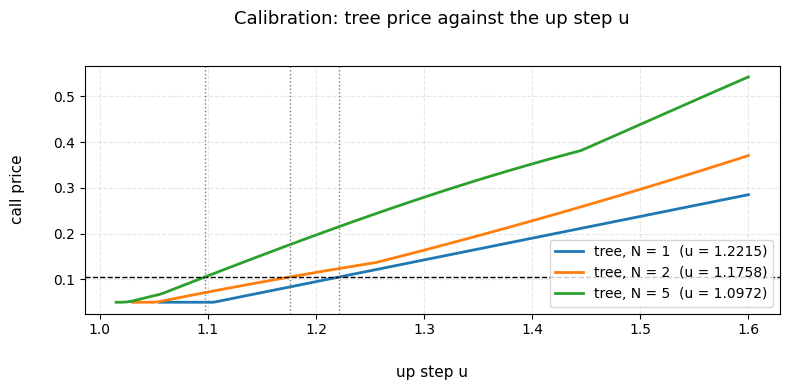

In [9]:
# Q1: test of calibrate (N = 1 against another root solver, prices out of range, picture)
import numpy as np
from scipy.optimize import brentq
from plotter import my_plotter
# black_scholes_eur_call, balanced_tree_call_price, calibrate, price_range: cells above

spot, strike, maturity, df_annual = 1.0, 1.0, 1.0, 0.95
r = -np.log(df_annual)                                        # the same flat rate
target = black_scholes_eur_call(r=r, T=maturity, S0=spot, sigma=0.2, K=strike)[0]
print(f"target price (Black-Scholes of Homework 1, sigma = 0.2): {target:.6f}")

# (a) one step: calibrate against scipy.optimize.brentq on V(u) - V* (another root solver)
u = calibrate(target, spot, strike, maturity, 1, df_annual)
DF = df_annual ** maturity
u_brentq = brentq(lambda x: balanced_tree_call_price(spot, strike, maturity, 1, df_annual, x)
                  - target, 1 / DF + 1e-10, 2 / DF - 1e-10, xtol=1e-14)
print(f"N = 1: calibrate u = {u:.10f},  brentq u = {u_brentq:.10f}")

# (b) prices that the tree cannot give (Step 2): calibrate raises ValueError
for price in [0.60, 0.04]:
    try:
        calibrate(price, spot, strike, maturity, 1, df_annual)
    except ValueError as error:
        print("ValueError:", error)

# (c) picture: tree price against u for N = 1, 2, 5; the calibrated u is where it meets the target
u_grid = np.linspace(1.0, 1.6, 121)
curves, names, u_cal = [], [], []
for steps in [1, 2, 5]:
    DF = df_annual ** (maturity / steps)
    curves.append([balanced_tree_call_price(spot, strike, maturity, steps, df_annual, x)
                   if 1 / DF < x < 2 / DF else np.nan for x in u_grid])
    u_cal.append(calibrate(target, spot, strike, maturity, steps, df_annual))
    names.append(f"tree, N = {steps}  (u = {u_cal[-1]:.4f})")
fig, ax = my_plotter(u_grid, curves,
                     layout={"title": "Calibration: tree price against the up step u",
                             "x_label": "up step u", "y_label": "call price",
                             "hline": target, "vlines": u_cal, "grid": True,
                             "title_fontsize": 13, "label_fontsize": 11, "legend_fontsize": 10,
                             "linewidth": 2, "colors": ["tab:blue", "tab:orange", "tab:green"]},
                     names=names)

**Result**: for $N = 1$, `calibrate` gives $u = 1.2214640224$, the same as `brentq`; prices outside $(0.05,\ 0.525)$ raise `ValueError`; in the plot each curve meets the target price at its calibrated $u$.